# Divergence



Divergence in a vector field is a measure of how much a the flow is expanding or contracting around a given point. It is quantifiying the rate which the flow is exiting or entering a point. Positive divergence means that the flow is locally expanding and negative divergence means it's contracting. Zero divergence means that the flow locally preserves volume.

The divergence of a first order dynamical system,

$$
\dot{X}=F(X),
$$

is

$$
\operatorname{div}(F)=tr(\frac{dF}{dX})
$$

Illustrating this with a 2d vector field of the system where

$$
\dot{X}=F(X)=(-x,-y),
$$

we get the following vector field.

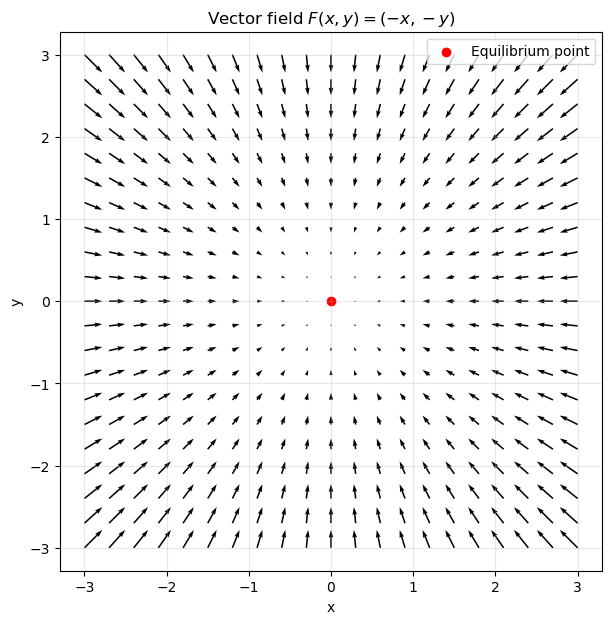

In [3]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-3, 3, 21)
y = np.linspace(-3, 3, 21)
X, Y = np.meshgrid(x, y)

U = -X
V = -Y

plt.figure(figsize=(7, 7))
plt.quiver(X, Y, U, V)
plt.scatter(0, 0, color="red", label="Equilibrium point")
plt.xlabel("x")
plt.ylabel("y")
plt.title(r"Vector field $F(x,y)=(-x,-y)$")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In this case $div(F)=-2$ throughout the entire vector field, meaning that the flow is locally contracting everywhere. Only the origin is a sink point since it is the only equilibrium point and all trajectories converge towards it.

### What does it mean that if $\operatorname{div}(F)=0$?

When the divergence is zero you can see it as the area is perserved, in a 2d vector field, when following a region of points. 

Looking at $$\dot(X) = F(X) = (x,-y)$$, we see that $$div(F)=dx/dx + d(-y)/dy = 1-1=0$$. The flow expands in the x direction and decreases in y-direction, which cancels out. This leads to when looking at a region of point, the area will remain the same no matter how many steps into the future you take. 


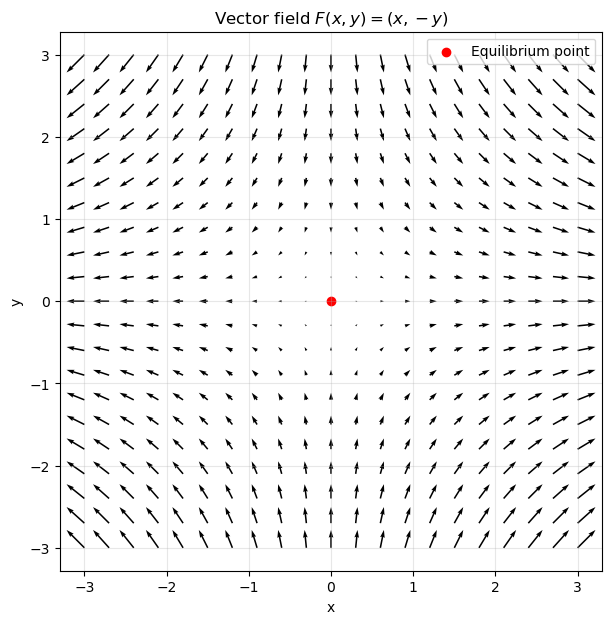

In [4]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-3, 3, 21)
y = np.linspace(-3, 3, 21)

X, Y = np.meshgrid(x, y)

U = X
V = -Y

plt.figure(figsize=(7, 7))
plt.quiver(X, Y, U, V)
plt.scatter(0, 0, color="red", label="Equilibrium point")

plt.xlabel("x")
plt.ylabel("y")
plt.title(r"Vector field $F(x,y)=(x,-y)$")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Polygon
from IPython.display import HTML

x = np.linspace(-4, 4, 17)
y = np.linspace(-4, 4, 17)
X, Y = np.meshgrid(x, y)

fig, ax = plt.subplots(figsize=(6, 6))
ax.quiver(X, Y, X, -Y, color="gray")

square0 = np.array([[-1, -1], [1, -1], [1, 1], [-1, 1]], dtype=float)
ax.add_patch(Polygon(square0, closed=True, fill=False, linestyle="--"))

square = Polygon(square0, closed=True, color="blue", alpha=0.3)
ax.add_patch(square)

text = ax.text(-3.8, 3.4, "")

ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_aspect("equal")
ax.grid()

t_values = np.linspace(0, 1.5, 100)

def update(i):
    t = t_values[i]
    pts = square0.copy()
    pts[:, 0] *= np.exp(t)
    pts[:, 1] *= np.exp(-t)
    square.set_xy(pts)
    text.set_text(f"t = {t:.2f}")
    return square, text

anim = FuncAnimation(fig, update, frames=len(t_values), interval=80, blit=True)

plt.close(fig)
HTML(anim.to_jshtml())

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Polygon
from IPython.display import HTML

x = np.linspace(-4, 4, 17)
y = np.linspace(-4, 4, 17)
X, Y = np.meshgrid(x, y)

fig, ax = plt.subplots(figsize=(6, 6))
ax.quiver(X, Y, -Y, X, color="gray")

square0 = np.array([[0.1, 0.1], [2.1, 0.1], [1.7, 2.1], [0.1, 2.1]], dtype=float)
ax.add_patch(Polygon(square0, closed=True, fill=False, linestyle="--"))

square = Polygon(square0, closed=True, color="blue", alpha=0.3)
ax.add_patch(square)

text = ax.text(-3.8, 3.4, "")

ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_aspect("equal")
ax.grid()

t_values = np.linspace(0, 2*np.pi, 100)

def update(i):
    t = t_values[i]
    pts = square0.copy()

    pts[:, 0] = square0[:, 0]*np.cos(t) - square0[:, 1]*np.sin(t)
    pts[:, 1] = square0[:, 0]*np.sin(t) + square0[:, 1]*np.cos(t)

    square.set_xy(pts)
    text.set_text(f"t = {t:.2f}")
    return square, text

anim = FuncAnimation(fig, update, frames=len(t_values), interval=80, blit=True)

plt.close(fig)
HTML(anim.to_jshtml())

The perservation of area is only true since $div(F) = 0$ for the whole vector field. The area is only preserved for the region in which the $div(F)=0$.

A system with $div(F)=0$ cannot have asymptotically stable equilibrium points

# Curl

Curl describes the local rotation of the flow. Positive curl 
indicates counterclockwise rotation, while negative curl 
indicates clockwise rotation.

For a two-dimensional vector field

$$
F(x,y)=
\begin{pmatrix}
f(x,y)\\
g(x,y)
\end{pmatrix},
$$

the curl is defined as

$$
\operatorname{curl}(F)
=\frac{\partial g}{\partial x}
-\frac{\partial f}{\partial y}.
$$

### What does it mean when $\operatorname{curl}(F)=0$?

An interesting property of a vector field with zero curl is 
that we can define a scalar function $\phi$, called a 
potential function, whose gradient is equal to the 
vector field $F$.

$$
F=\nabla\phi.
$$


We can therefore rewrite our first-order dynamical system

$$
\dot{X}=F(X)
$$

as

$$
\dot{X}=\nabla\phi(X).
$$


Since the vector field is given by the gradient of a potential 
function $\phi$, a particle travelling in the vector field will 
always move in the direction of the gradient. 

To investigate how the potential changes along a trajectory 
$X(t)$, we differentiate with respect to time using the chain rule:

$$
\frac{d}{dt}\phi(X(t))
=\nabla\phi(X(t))\cdot\dot{X}(t).
$$

Since $\dot{X}=\nabla\phi(X)$, we get

$$
\frac{d}{dt}\phi(X(t))
=\nabla\phi(X(t))\cdot\nabla\phi(X(t))
=\|\nabla\phi(X(t))\|^2\geq 0.
$$

This means that the potential function is strictly increasing 
along a trajectory, except at equilibrium points where 
$\nabla\phi(X)=0$.


An implication of this is that a particle cannot 
follow a nonconstant periodic trajectory.

If a trajectory were periodic with period $T>0$, we would have

$$
X(t+T)=X(t).
$$

Since the particle returns to the same position, the potential 
would also have to return to the same value:

$$
\phi(X(t+T))=\phi(X(t)).
$$

However this contradicts the fact that the potential is 
strictly increasing along a nonconstant trajectory.

### Equilibrium points

Another interesting implication of describing the vector field 
using a potential function is that we can investigate the 
equilibrium points of the system by looking at the 
potential function.

An equilibrium point $X^*$ is defined by

$$
F(X^*)=0.
$$

Since $F=\nabla\phi$ this is equivalent to

$$
\nabla\phi(X^*)=0.
$$

This means that the equilibrium points of the dynamical system 
correspond to the critical points of the potential function.

- Local maxima of $\phi$ correspond to sinks.
- Local minima of $\phi$ correspond to sources.
- Saddle points of $\phi$ correspond to saddle equilibria.

This makes it possible to investigate the stability of 
equilibrium points by studying the 
potential function.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

x = np.linspace(-4, 4, 17)
y = np.linspace(-4, 4, 17)
X, Y = np.meshgrid(x, y)

t = np.linspace(0, 2, 100)

# Particle trajectory and potential
xt = 0.5 * np.exp(t)
yt = 2 * np.exp(-t)
phi = (xt**2 - yt**2)/2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.quiver(X, Y, X, -Y, color="gray")
ax1.set_xlim(-4, 4)
ax1.set_ylim(-4, 4)
ax1.set_aspect("equal")
ax1.set_title("Particle trajectory")
ax1.grid()

particle, = ax1.plot([], [], "ro")
trajectory, = ax1.plot([], [], "r-")

ax2.set_xlim(0, 2)
ax2.set_ylim(phi.min()-0.5, phi.max()+0.5)
ax2.set_xlabel("Time")
ax2.set_ylabel(r"$\phi(X(t))$")
ax2.set_title("Potential")
ax2.grid()

potential, = ax2.plot([], [], "b-")

def update(i):
    particle.set_data([xt[i]], [yt[i]])
    trajectory.set_data(xt[:i+1], yt[:i+1])
    potential.set_data(t[:i+1], phi[:i+1])

    return particle, trajectory, potential

anim = FuncAnimation(fig, update, frames=len(t), interval=80, blit=True)

plt.close(fig)
HTML(anim.to_jshtml())

From the animation, we can observe that the potential function
is strictly increasing as the particle travels through the
vector field. it is described by

$$
F(x,y)=
\begin{pmatrix}
x\\
-y
\end{pmatrix},
$$

which satisfies $\operatorname{curl}(F)=0$ and has the
potential function

$$
\phi(x,y)=\frac{x^2-y^2}{2}.
$$
